# UTA Softball: What Makes a Pitch Different?
**DATA 4380 — Final study | UTA vs. South Dakota State, March 14, 2026**

This notebook answers two questions:

1. **Which pitch characteristics are associated with our three measurable outcomes?** We study direct strikes, strikes added, and batter swings separately. Then we compare the useful features across all three.
2. **Can we find different pitching profiles using speed, spin, and movement?** We study both overall pitch groups and differences *within* each pitcher's pitches.

We start with the real tracking file, keep the original data unchanged, and show every result **under the code that creates it**. No charts or tables are exported. A result can be useful without proving what *caused* it.

**Source check:** [Official UTA box score](https://utamavs.com/sports/softball/stats/2026/south-dakota-state/boxscore/21014). It confirms UTA won 6–4, but some South Dakota State pitcher names/counts in the tracking file disagree with the official record. **We do not guess replacement names.** Pitcher-level and leave-one-pitcher-out results are *preliminary* until corrected.

## 1. Load the tracking data
One row is one recorded pitch. We use pandas for tables and seaborn/matplotlib for charts.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 15)

# Keep the CSV beside this notebook. Either filename below works.
file = next((Path(name) for name in ["South Dakota State_0466(1).csv",
                                      "South Dakota State_0466.csv"] if Path(name).exists()), None)
if file is None:
    raise FileNotFoundError("Put the original South Dakota State CSV in the same folder as this notebook.")

df = pd.read_csv(file, low_memory=False)
df["Pitcher"] = df["Pitcher"].astype(str).str.split().str.join(" ")
print(f"Original dataset: {df.shape[0]} pitches, {df.shape[1]} columns")
print(f"Numerical columns: {df.select_dtypes(include='number').shape[1]}")
print(f"Text/object columns: {df.select_dtypes(exclude='number').shape[1]}")
display(df[["Pitcher", "RelSpeed", "SpinRate", "PlateLocSide", "PitchCall"]].head())

Original dataset: 259 pitches, 125 columns
Numerical columns: 98
Text/object columns: 27


,Pitcher,RelSpeed,SpinRate,PlateLocSide,PitchCall
0,Kynlee Bowlin,59.768053,1478.556580,0.547286,StrikeCalled
1,Kynlee Bowlin,49.749370,955.292288,0.238784,Foul
2,Kynlee Bowlin,59.408574,1678.935476,0.566911,InPlay
3,Kynlee Bowlin,59.209019,1567.336673,0.135454,Foul
4,Kynlee Bowlin,60.856576,1600.484647,0.564103,BallCalled


## 2. Check missing values before changing anything
A dark cell means the measurement is present; a light cell means it is missing. Missing values are not always mistakes: for example, exit speed is usually unavailable when there was no batted ball. We do not replace everything with zero.

,Missing,Percent
TaggedPitchType,132,51.0
SpinRate,23,8.9
InducedVertBreak,23,8.9
HorzBreak,23,8.9
RelSpeed,20,7.7
PlateLocSide,20,7.7
PlateLocHeight,20,7.7
PitchCall,1,0.4
Strikes,0,0.0
Balls,0,0.0


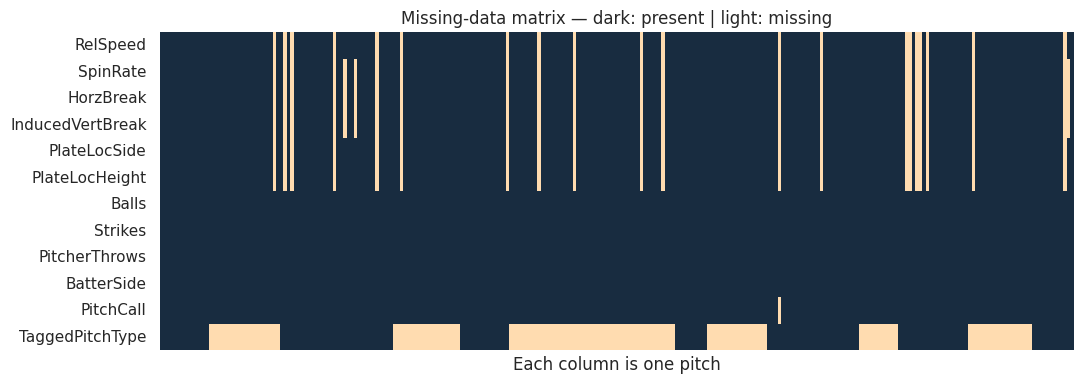

In [2]:
numeric = ["RelSpeed", "SpinRate", "HorzBreak", "InducedVertBreak",
           "PlateLocSide", "PlateLocHeight", "Balls", "Strikes"]
categorical = ["PitcherThrows", "BatterSide"]
main_columns = numeric + categorical + ["PitchCall", "TaggedPitchType"]

missing = df[main_columns].isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"Missing": missing, "Percent": (missing / len(df) * 100).round(1)}))

plt.figure(figsize=(11, 4))
sns.heatmap(df[main_columns].isna().T, cmap=["#182C40", "#FFDCB0"],
            cbar=False, xticklabels=False)
plt.title("Missing-data matrix — dark: present | light: missing")
plt.xlabel("Each column is one pitch")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 3. Turn `PitchCall` into three clear outcomes
`PitchCall` has several categories with very different counts. Instead of saying a pitch is simply "good" or "bad," we ask three separate yes/no questions:

- **Direct strike:** called strike or swing-and-miss.
- **Strike added:** direct strike, or ordinary foul with fewer than two strikes beforehand.
- **Batter swing:** swinging strike, foul, or ball hit into play.

These are **three targets** (`y`), not three kinds of pitches. One pitch can count as a "yes" for multiple targets. They are useful *proxies*, not complete measures of winning or pitcher talent. We exclude three hit-by-pitches and the one missing `PitchCall` for comparable targets; this is a scope choice, not a statement that HBP is irrelevant.

,Number of pitches
PitchCall,
BallCalled,98
Foul,58
InPlay,52
StrikeCalled,36
StrikeSwinging,11
HitByPitch,3
NaN,1


,Yes,Total,Yes (%)
Direct strike,47,255,18.4
Strike added,86,255,33.7
Batter swing,121,255,47.5


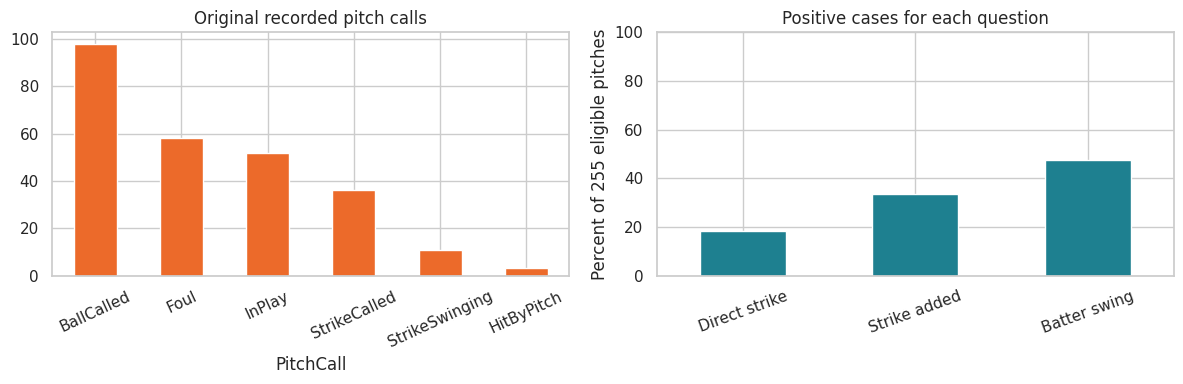

In [3]:
display(df["PitchCall"].value_counts(dropna=False).rename("Number of pitches").to_frame())

valid_calls = ["BallCalled", "StrikeCalled", "StrikeSwinging", "Foul", "InPlay"]
study = df[df["PitchCall"].isin(valid_calls)].copy().reset_index(drop=True)

study["Direct strike"] = study["PitchCall"].isin(["StrikeCalled", "StrikeSwinging"]).astype(int)
study["Strike added"] = (study["Direct strike"].eq(1) |
    (study["PitchCall"].eq("Foul") & study["Strikes"].lt(2))).astype(int)
study["Batter swing"] = study["PitchCall"].isin(["StrikeSwinging", "Foul", "InPlay"]).astype(int)
targets = ["Direct strike", "Strike added", "Batter swing"]

rates = pd.DataFrame({"Yes": study[targets].sum(), "Total": len(study)})
rates["Yes (%)"] = (100 * rates["Yes"] / rates["Total"]).round(1)
display(rates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["PitchCall"].value_counts().plot.bar(ax=axes[0], color="#EC6A2A")
axes[0].set_title("Original recorded pitch calls"); axes[0].tick_params(axis="x", rotation=25)
rates["Yes (%)"].plot.bar(ax=axes[1], color="#1E8090")
axes[1].set_title("Positive cases for each question"); axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Percent of 255 eligible pitches"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 4. Understand the pitch features before modeling
We use **eight numerical measurements** and **two categorical variables**. Velocity, spin, and break describe how the ball travels. Location describes where it crossed the plate. The ball-strike count describes the situation before the pitch.

We leave out `PitchCall`, batted-ball results, runs, and other after-the-pitch fields from the model inputs because they could reveal the answer. We also leave out pitch type: many labels are missing for one entire team.

,Column,Meaning
0,RelSpeed,Velocity
1,SpinRate,Spin rate
2,HorzBreak,Horizontal break
3,InducedVertBreak,Vertical break
4,PlateLocSide,Plate side
5,PlateLocHeight,Plate height
6,Balls,Balls before pitch
7,Strikes,Strikes before pitch
8,PitcherThrows,Pitcher hand
9,BatterSide,Batter side


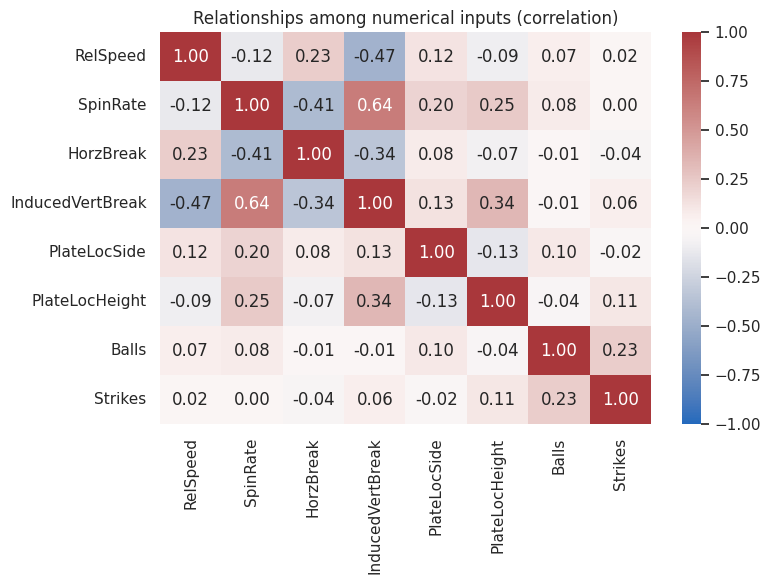

In [4]:
feature_names = {
    "RelSpeed": "Velocity", "SpinRate": "Spin rate",
    "HorzBreak": "Horizontal break", "InducedVertBreak": "Vertical break",
    "PlateLocSide": "Plate side", "PlateLocHeight": "Plate height",
    "Balls": "Balls before pitch", "Strikes": "Strikes before pitch",
    "PitcherThrows": "Pitcher hand", "BatterSide": "Batter side"
}
display(pd.DataFrame({"Column": list(feature_names), "Meaning": list(feature_names.values())}))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(study[numeric].corr(), cmap="vlag", vmin=-1, vmax=1,
            annot=True, fmt=".2f", ax=ax)
ax.set_title("Relationships among numerical inputs (correlation)")
plt.tight_layout(); plt.show()

## 5. Start with statistics: which measurements go with each outcome?
A **point-biserial correlation** checks whether a numerical measurement tends to be larger or smaller when a target is 1 rather than 0. Positive and negative show direction; values near zero show weak *linear* relationships.

**Be careful:** pitches from the same player are related, so these are descriptive associations—not causal effects, independent-observation p-values, or proof about future games.

,Direct strike,Strike added,Batter swing
Velocity,0.066,0.098,0.013
Spin rate,0.071,0.009,-0.018
Horizontal break,0.065,0.031,-0.071
Vertical break,0.015,0.020,0.008
Plate side,0.045,0.014,0.061
Plate height,-0.038,-0.038,-0.004
Balls before pitch,-0.049,-0.143,0.088
Strikes before pitch,-0.242,-0.301,0.351


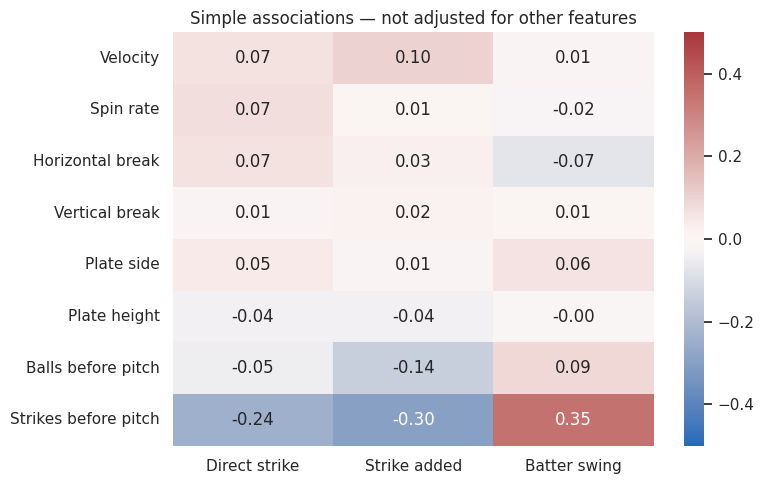

In [5]:
from scipy.stats import pointbiserialr

associations = pd.DataFrame(index=numeric, columns=targets, dtype=float)
for col in numeric:
    for outcome in targets:
        subset = study[[col, outcome]].dropna()
        if subset[col].nunique() > 1 and subset[outcome].nunique() == 2:
            associations.loc[col, outcome] = pointbiserialr(subset[outcome], subset[col]).statistic

associations = associations.rename(index=feature_names)
display(associations.round(3))
plt.figure(figsize=(8, 5))
sns.heatmap(associations.astype(float), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-0.5, vmax=0.5)
plt.title("Simple associations — not adjusted for other features")
plt.tight_layout(); plt.show()

## 6. Does the game count relate to swings?
Before building a model, compare the observed swing rate at 0, 1, or 2 strikes. This can explain why game context belongs in the analysis.

,Pitches,Swing rate
Strikes,,
0,113,29.2
1,65,52.3
2,77,70.1


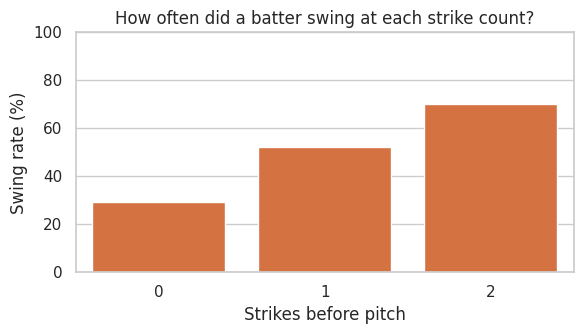

In [6]:
count_table = study.groupby("Strikes")["Batter swing"].agg(["size", "mean"])
count_table.columns = ["Pitches", "Swing rate"]
count_table["Swing rate"] = (count_table["Swing rate"] * 100).round(1)
display(count_table)
plt.figure(figsize=(6, 3.5))
sns.barplot(x=count_table.index, y=count_table["Swing rate"], color="#EC6A2A")
plt.title("How often did a batter swing at each strike count?")
plt.xlabel("Strikes before pitch"); plt.ylabel("Swing rate (%)"); plt.ylim(0, 100)
plt.tight_layout(); plt.show()

## 7. Compare three supervised models on **all three targets**
For each question, we compare:

- **Baseline:** predicts the overall yes-rate learned from training pitches.
- **Logistic regression:** a simple regularized classifier (not linear regression).
- **Random forest:** multiple decision trees that can learn nonlinear patterns.

We hold out one **recorded pitcher** at a time rather than randomly mixing that pitcher's throws across train/test. **This remains provisional** because some recorded pitcher identities conflict with official records. Each training fold learns its own imputation medians, scaling, and category encoding: no peeking at held-out pitches.

,Outcome,Model,ROC-AUC,Average precision
0,Direct strike,Baseline,0.419,0.164
1,Direct strike,Logistic regression,0.591,0.258
2,Direct strike,Random forest,0.650,0.316
3,Strike added,Baseline,0.460,0.319
4,Strike added,Logistic regression,0.616,0.418
5,Strike added,Random forest,0.779,0.626
6,Batter swing,Baseline,0.421,0.437
7,Batter swing,Logistic regression,0.623,0.583
8,Batter swing,Random forest,0.672,0.618


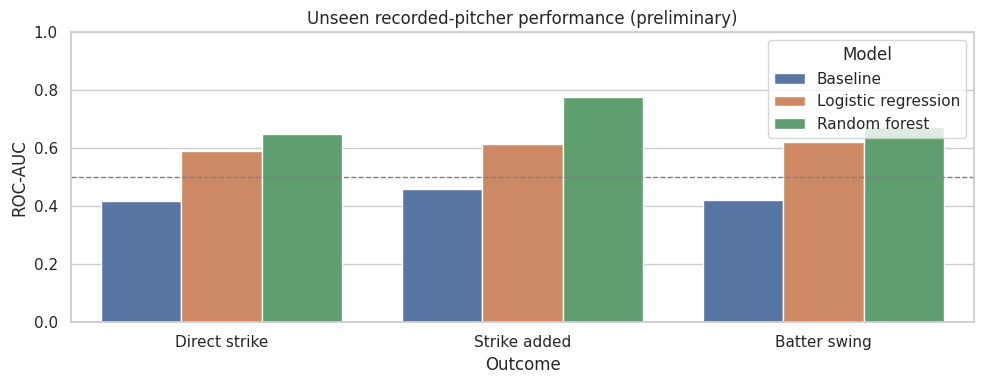

In [7]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

folds = list(LeaveOneGroupOut().split(study, groups=study["Pitcher"]))

# Each model gets its own preprocessing (learned from training data only).
def prepare(numeric_cols, category_cols):
    steps = []
    if numeric_cols:
        steps.append(("numbers", Pipeline([
            ("fill", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric_cols))
    if category_cols:
        steps.append(("categories", Pipeline([
            ("fill", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore"))
        ]), category_cols))
    return ColumnTransformer(steps)

def make_model(name, num=numeric, cat=categorical):
    if name == "Baseline":
        classifier = DummyClassifier(strategy="prior")
    elif name == "Logistic regression":
        classifier = LogisticRegression(C=0.3, max_iter=3000, random_state=42)
    else:
        classifier = RandomForestClassifier(n_estimators=90, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1)
    return Pipeline([("prepare", prepare(num, cat)), ("model", classifier)])

# Return one held-out prediction for each pitch; never evaluate on training pitches.
def held_out_probabilities(model_name, outcome, num=numeric, cat=categorical,
                           drop_incomplete_training=False):
    X = study[num + cat]
    y = study[outcome]
    predictions = np.full(len(study), np.nan)
    for train, test in folds:
        if drop_incomplete_training:
            train = np.array([i for i in train if not X.iloc[i].isna().any()])
        model = make_model(model_name, num, cat)
        model.fit(X.iloc[train], y.iloc[train])
        predictions[test] = model.predict_proba(X.iloc[test])[:, 1]
    return predictions

results = []
predictions = {}
for outcome in targets:
    for name in ["Baseline", "Logistic regression", "Random forest"]:
        probabilities = held_out_probabilities(name, outcome)
        predictions[(outcome, name)] = probabilities
        results.append({"Outcome": outcome, "Model": name,
            "ROC-AUC": roc_auc_score(study[outcome], probabilities),
            "Average precision": average_precision_score(study[outcome], probabilities)})

scores = pd.DataFrame(results)
display(scores.round(3))
plt.figure(figsize=(10, 4))
sns.barplot(data=scores, x="Outcome", y="ROC-AUC", hue="Model")
plt.ylim(0, 1); plt.axhline(.5, color="gray", ls="--", lw=1)
plt.title("Unseen recorded-pitcher performance (preliminary)")
plt.tight_layout(); plt.show()

## 8. Which *groups* of features helped predict each outcome?
Here we make a fair comparison by giving the **same random forest** different information:

1. **Physical only:** velocity, spin, horizontal and vertical break.
2. **Count + location:** pre-pitch balls and strikes, plate height and side.
3. **All 8 numerical:** both groups together.
4. **Full 10 features:** eight numerical plus pitcher/batter handedness.

This separates the value of **ball physics** from **game context**. An important caveat: the `Strike added` rule itself uses the existing strike count, so a strong count model is partly predictable by definition.

Outcome,Batter swing,Direct strike,Strike added
Features,,,
All 8 numerical,0.689,0.695,0.808
Count / location,0.723,0.700,0.826
Full 10 features,0.672,0.650,0.779
Speed / spin / movement,0.435,0.552,0.517


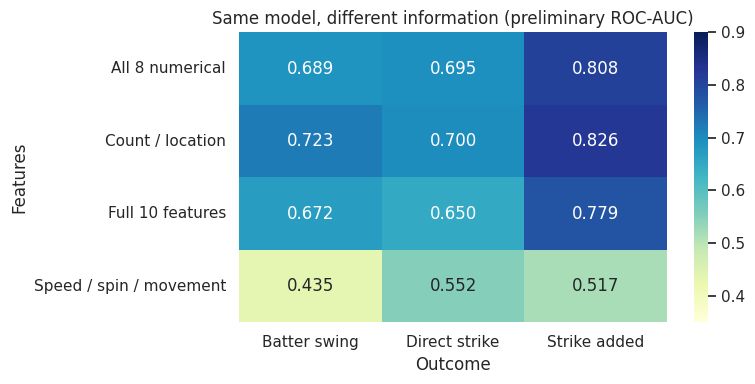

In [8]:
physical_cols = ["RelSpeed", "SpinRate", "HorzBreak", "InducedVertBreak"]
context_cols = ["Balls", "Strikes", "PlateLocSide", "PlateLocHeight"]
feature_sets = {
    "Speed / spin / movement": (physical_cols, []),
    "Count / location": (context_cols, []),
    "All 8 numerical": (numeric, []),
    "Full 10 features": (numeric, categorical)
}

set_rows = []
for outcome in targets:
    for label, (num, cat) in feature_sets.items():
        p = predictions[(outcome, "Random forest")] if label == "Full 10 features" else             held_out_probabilities("Random forest", outcome, num, cat)
        set_rows.append({"Outcome": outcome, "Features": label,
                         "ROC-AUC": roc_auc_score(study[outcome], p)})

set_table = pd.DataFrame(set_rows)
display(set_table.pivot(index="Features", columns="Outcome", values="ROC-AUC").round(3))
plt.figure(figsize=(8, 4))
sns.heatmap(set_table.pivot(index="Features", columns="Outcome", values="ROC-AUC"),
            annot=True, fmt=".3f", cmap="YlGnBu", vmin=.35, vmax=.9)
plt.title("Same model, different information (preliminary ROC-AUC)")
plt.tight_layout(); plt.show()

## 9. Which **individual features** matter for each prediction?
The full-model ROC-AUC tells us whether the whole model works, not which input helped. We use a simple check called **held-out permutation importance**:

1. Train on five recorded pitchers.
2. Make predictions on the held-out pitcher normally.
3. Shuffle **one** input column within that held-out set, and predict again.
4. Measure how much ROC-AUC falls. Repeat this twice to reduce random variation.

If scrambling a feature makes predictions worse, it was useful *to this fitted model*. Negative or near-zero values do **not** mean a feature is bad or physically unimportant. Features can overlap and the data is small. This is **predictive importance, not cause and effect**.

Outcome,Batter swing,Direct strike,Strike added,Average across outcomes
Feature,,,,
Strikes before pitch,0.112,0.048,0.153,0.104
Plate height,0.063,-0.001,0.060,0.041
Plate side,0.019,0.045,0.050,0.038
Vertical break,-0.001,0.011,-0.001,0.003
Balls before pitch,0.003,-0.002,0.007,0.003
Horizontal break,-0.004,-0.001,0.007,0.001
Pitcher hand,0.000,0.000,0.000,0.000
Spin rate,-0.003,-0.001,0.002,-0.001
Batter side,-0.004,-0.002,0.003,-0.001


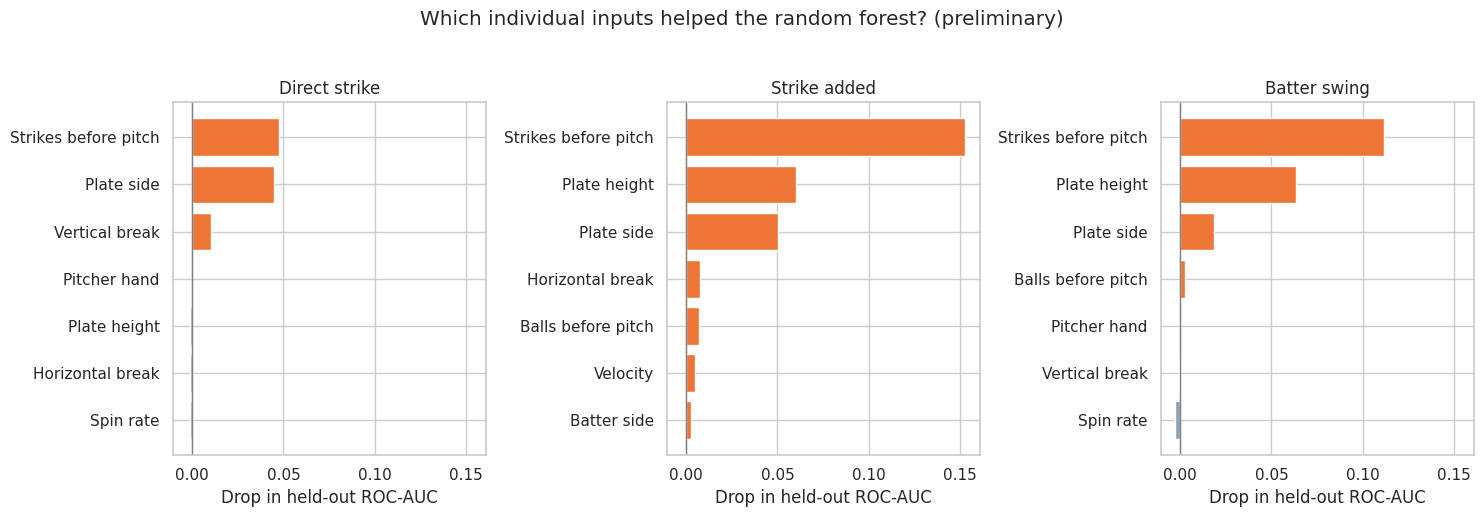

In [9]:
from collections import defaultdict

rng = np.random.default_rng(2026)
importance_rows = []
Xall = study[numeric + categorical]

for outcome in targets:
    y = study[outcome].to_numpy()
    baseline_predictions = predictions[(outcome, "Random forest")]
    baseline_auc = roc_auc_score(y, baseline_predictions)
    scrambled = {name: np.full((2, len(study)), np.nan) for name in numeric + categorical}

    # Refit on each training fold, then shuffle only the held-out pitch values.
    for train, test in folds:
        model = make_model("Random forest")
        model.fit(Xall.iloc[train], y[train])
        original_test = Xall.iloc[test].copy()
        for feature in numeric + categorical:
            for repeat in range(2):
                shuffled_test = original_test.copy()
                shuffled_test[feature] = rng.permutation(shuffled_test[feature].to_numpy())
                scrambled[feature][repeat, test] = model.predict_proba(shuffled_test)[:, 1]

    for feature in numeric + categorical:
        drops = [baseline_auc - roc_auc_score(y, scrambled[feature][rep]) for rep in range(2)]
        importance_rows.append({"Outcome": outcome, "Feature": feature_names[feature],
                                "ROC-AUC drop": np.mean(drops)})

importance = pd.DataFrame(importance_rows)
importance_table = importance.pivot(index="Feature", columns="Outcome", values="ROC-AUC drop")
importance_table["Average across outcomes"] = importance_table[targets].mean(axis=1)
importance_table = importance_table.sort_values("Average across outcomes", ascending=False)
display(importance_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)
for ax, outcome in zip(axes, targets):
    top = importance[importance["Outcome"] == outcome].sort_values("ROC-AUC drop").tail(7)
    colors = ["#EE7536" if v > 0 else "#8AA2B2" for v in top["ROC-AUC drop"]]
    ax.barh(top["Feature"], top["ROC-AUC drop"], color=colors)
    ax.axvline(0, color="gray", lw=1)
    ax.set_title(outcome)
    ax.set_xlabel("Drop in held-out ROC-AUC")
fig.suptitle("Which individual inputs helped the random forest? (preliminary)", y=1.03)
plt.tight_layout(); plt.show()

## 10. What helped across **all three** outcomes?
There is **no single real-world "overall success" label** in this dataset, so we should not invent one or say the best feature guarantees wins. For a helpful summary, we average each feature's **ROC-AUC drop** across the three *separate* prediction tasks.

The average is a **model-comparison summary only**. It weighs the three questions equally; it is not a new trained target, a causal effect, or a measure of season success. Features near the top are reasonable topics for future investigation.

,Mean ROC-AUC drop
Feature,
Strikes before pitch,0.104
Plate height,0.041
Plate side,0.038
Vertical break,0.003
Balls before pitch,0.003
Horizontal break,0.001
Pitcher hand,0.000
Spin rate,-0.001
Batter side,-0.001


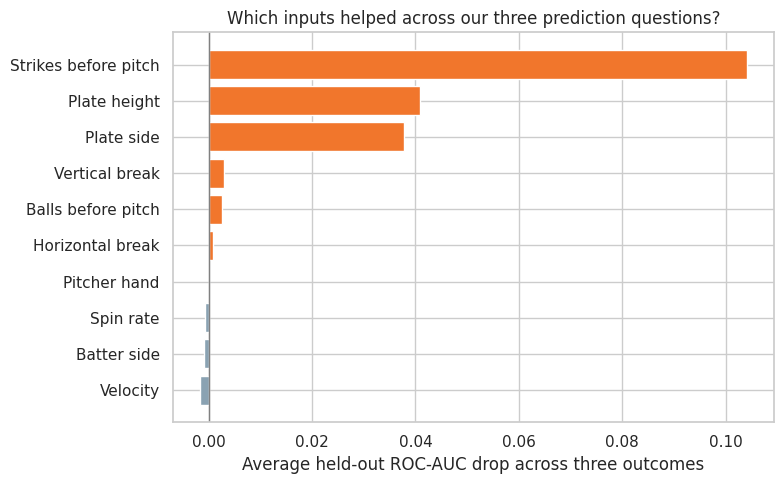

In [10]:
overall = importance_table["Average across outcomes"].sort_values()
display(overall.sort_values(ascending=False).rename("Mean ROC-AUC drop").round(3).to_frame())
plt.figure(figsize=(8, 5))
plt.barh(overall.index, overall.values,
         color=["#F1762C" if x > 0 else "#8AA2B2" for x in overall.values])
plt.axvline(0, color="gray", lw=1)
plt.xlabel("Average held-out ROC-AUC drop across three outcomes")
plt.title("Which inputs helped across our three prediction questions?")
plt.tight_layout(); plt.show()

## 11. Imputation or deletion: did keeping incomplete pitches help?
We compare **logistic regression** trained in two ways:

- **Impute:** keep all available training rows; fill numerical gaps with each training fold's median.
- **Delete:** train on complete rows only.

For fairness, we test both on the **same held-out complete-case pitches**. So any difference comes from the *training strategy*, not a different test set. The earlier experiment suggested differences were small. Here we repeat it for all three targets.

**Statistical caution:** A tiny difference is not proof that the strategies are equivalent. There are only a few recorded pitchers. To show uncertainty, we also resample *whole pitchers*, not individual pitches, to get a rough interval for the ROC-AUC difference.

,Outcome,Imputation,Delete training rows,Difference
0,Direct strike,0.573,0.573,-0.000
1,Strike added,0.598,0.596,0.002
2,Batter swing,0.616,0.611,0.005


Same complete-case test pitches for both approaches: 233 / 255


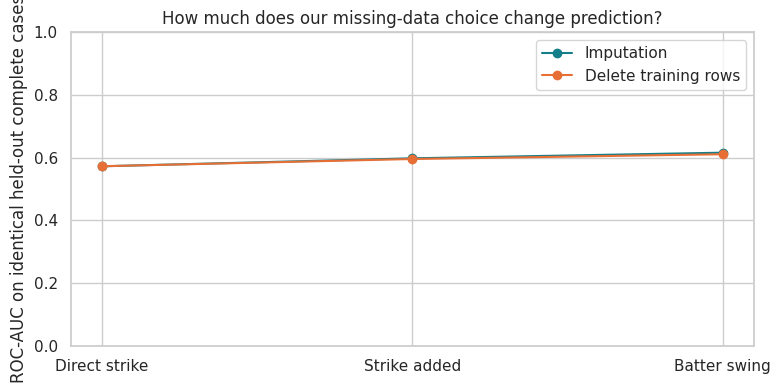

In [11]:
from sklearn.metrics import roc_auc_score

complete = study[numeric + categorical].notna().all(axis=1).to_numpy()
compare_rows = []
comparison_predictions = {}
for outcome in targets:
    y = study[outcome].to_numpy()
    p_keep = predictions[(outcome, "Logistic regression")]
    p_delete = held_out_probabilities("Logistic regression", outcome,
                                      drop_incomplete_training=True)
    keep_auc = roc_auc_score(y[complete], p_keep[complete])
    delete_auc = roc_auc_score(y[complete], p_delete[complete])
    comparison_predictions[outcome] = (p_keep, p_delete)
    compare_rows.append({"Outcome": outcome, "Imputation": keep_auc,
                         "Delete training rows": delete_auc,
                         "Difference": keep_auc - delete_auc})

missing_comparison = pd.DataFrame(compare_rows)
display(missing_comparison.round(3))
print(f"Same complete-case test pitches for both approaches: {complete.sum()} / {len(study)}")

fig, ax = plt.subplots(figsize=(8, 4))
for method, color in [("Imputation", "#147F89"), ("Delete training rows", "#E76F36")]:
    ax.plot(missing_comparison["Outcome"], missing_comparison[method],
            marker="o", label=method, color=color)
ax.set_ylim(0, 1); ax.set_ylabel("ROC-AUC on identical held-out complete cases")
ax.set_title("How much does our missing-data choice change prediction?")
ax.legend(); plt.tight_layout(); plt.show()

### A careful check of uncertainty
We build a rough **pitcher-level bootstrap interval** for the ROC-AUC difference (imputation minus deletion). We resample whole recorded pitchers because their pitches are related. With only six recorded groups—and misidentified pitchers—these intervals are unstable, so we treat them as sensitivity checks, **not proof of a statistical difference or equivalence**.

In [12]:
rng = np.random.default_rng(42)
pitcher_groups = study.loc[complete, "Pitcher"].to_numpy()
unique_pitchers = np.unique(pitcher_groups)
bootstrap_rows = []

for outcome in targets:
    y = study.loc[complete, outcome].to_numpy()
    p_keep, p_drop = comparison_predictions[outcome]
    p_keep, p_drop = p_keep[complete], p_drop[complete]
    deltas = []
    for _ in range(400):
        sampled = rng.choice(unique_pitchers, size=len(unique_pitchers), replace=True)
        indices = np.concatenate([np.flatnonzero(pitcher_groups == name) for name in sampled])
        if len(np.unique(y[indices])) < 2:
            continue
        deltas.append(roc_auc_score(y[indices], p_keep[indices]) -
                      roc_auc_score(y[indices], p_drop[indices]))
    bootstrap_rows.append({"Outcome": outcome,
        "Observed difference": roc_auc_score(y, p_keep) - roc_auc_score(y, p_drop),
        "Rough 95% lower": np.percentile(deltas, 2.5),
        "Rough 95% upper": np.percentile(deltas, 97.5)})

display(pd.DataFrame(bootstrap_rows).round(3))
print("Intervals show uncertainty; they cannot prove equal performance, especially with so few pitchers.")

,Outcome,Observed difference,Rough 95% lower,Rough 95% upper
0,Direct strike,-0.000,-0.012,0.018
1,Strike added,0.002,-0.007,0.012
2,Batter swing,0.005,-0.004,0.013


Intervals show uncertainty; they cannot prove equal performance, especially with so few pitchers.


## 12. Research Question 2: Can we find pitching profiles?
We use **four physical measurements**: velocity, spin, horizontal break, and vertical break. These are directly related to *how the ball travels*. We exclude count and batter outcome because our goal here is to group pitches by their flight characteristics—not whether they produced a strike.

First, standardize the measurements so RPM does not dominate mph simply because its numbers are larger. Then:

- **K-means** makes groups based on similarity in all four scaled measurements.
- **Silhouette** checks how separated those groups are.
- **PCA** summarizes the four measurements into two axes for a plot. PCA is for visualization here; K-means still uses all four measurements.

,Clusters,Silhouette
0,2,0.520
1,3,0.362
2,4,0.420


Pitches with all four physical measurements: 236
Variance shown by first two PCA axes: 76.0%


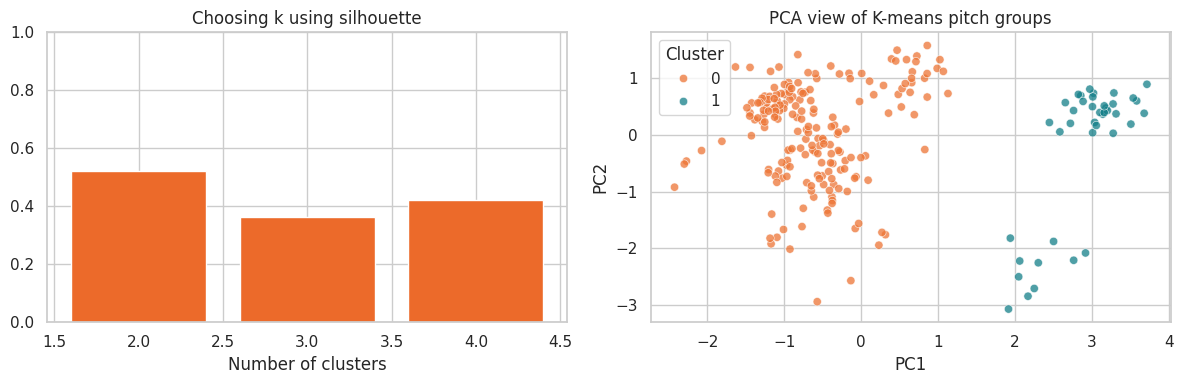

In [13]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Clustering doesn't require a pitch outcome, so use every pitch with physical data.
physical = df.dropna(subset=physical_cols).copy().reset_index(drop=True)
scaled = StandardScaler().fit_transform(physical[physical_cols])

silhouette_rows = []
for k in [2, 3, 4]:
    proposed = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(scaled)
    silhouette_rows.append({"Clusters": k, "Silhouette": silhouette_score(scaled, proposed)})
display(pd.DataFrame(silhouette_rows).round(3))

physical["Cluster"] = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(scaled)
coordinates = PCA(n_components=2).fit_transform(scaled)
physical["PC1"], physical["PC2"] = coordinates[:, 0], coordinates[:, 1]

pca_explained = PCA(n_components=2).fit(scaled).explained_variance_ratio_.sum()
print(f"Pitches with all four physical measurements: {len(physical)}")
print(f"Variance shown by first two PCA axes: {pca_explained * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar([r["Clusters"] for r in silhouette_rows],
            [r["Silhouette"] for r in silhouette_rows], color="#EC6A2A")
axes[0].set_title("Choosing k using silhouette")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylim(0, 1)
sns.scatterplot(data=physical, x="PC1", y="PC2", hue="Cluster",
                palette=["#ED7535", "#147F89"], ax=axes[1], alpha=.75)
axes[1].set_title("PCA view of K-means pitch groups")
plt.tight_layout(); plt.show()

## 13. Describe the clusters before calling them "styles"
K-means only gives labels 0 and 1. We examine their average speed, spin, and break, plus who threw the pitches. **If one cluster comes mainly from one person, K-means may be recognizing that pitcher's usual measurements rather than a broadly shared style.** This is why checking cluster membership matters.

,Number of pitches,Velocity,Spin rate,Horizontal break,Vertical break
Cluster,,,,,
0,196,65.9,1110.0,-0.4,-4.3
1,40,57.7,1467.1,-4.9,3.3


Cluster,0,1
Pitcher,,
Bella Macmahon,7,0
Grace Proctor,51,0
Keira Carrillo,17,0
Kynlee Bowlin,0,40
Maddie Furniss,72,0
Tayler Baker,49,0


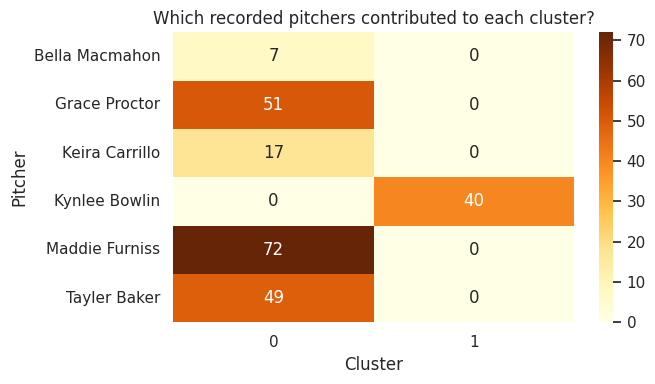

In [14]:
cluster_means = physical.groupby("Cluster")[physical_cols].mean().round(1)
cluster_means.insert(0, "Number of pitches", physical.groupby("Cluster").size())
display(cluster_means.rename(columns=feature_names))

cluster_members = pd.crosstab(physical["Pitcher"], physical["Cluster"])
display(cluster_members)
plt.figure(figsize=(7, 4))
sns.heatmap(cluster_members, annot=True, fmt="d", cmap="YlOrBr")
plt.title("Which recorded pitchers contributed to each cluster?")
plt.tight_layout(); plt.show()

## 14. A better follow-up: compare changes **within each pitcher**
The first clusters might mainly separate pitchers. To look for patterns that *more than one pitcher* might share, we also subtract each pitcher's average from their own measurements, then scale those deviations.

Example: a pitch marked +1 for speed is fast **relative to that pitcher's usual speed**, not necessarily fast compared with everyone else. This is a different question, so these groups are **relative pitch patterns**, not verified riseballs/curveballs or universal styles.

**Limitation:** This still relies on pitcher names that need official verification.

,k,Silhouette
0,2,0.538
1,3,0.249
2,4,0.240


Relative cluster,Relative group 0 (%),Relative group 1 (%)
Pitcher,,
Bella Macmahon,85.7,14.3
Grace Proctor,92.2,7.8
Keira Carrillo,94.1,5.9
Kynlee Bowlin,75.0,25.0
Maddie Furniss,100.0,0.0
Tayler Baker,85.7,14.3


Mean deviations from each pitcher's own average in each relative group:


,Velocity,Spin rate,Horizontal break,Vertical break
Relative cluster,,,,
0,0.89,30.11,0.07,0.31
1,-8.28,-278.87,-0.65,-2.87


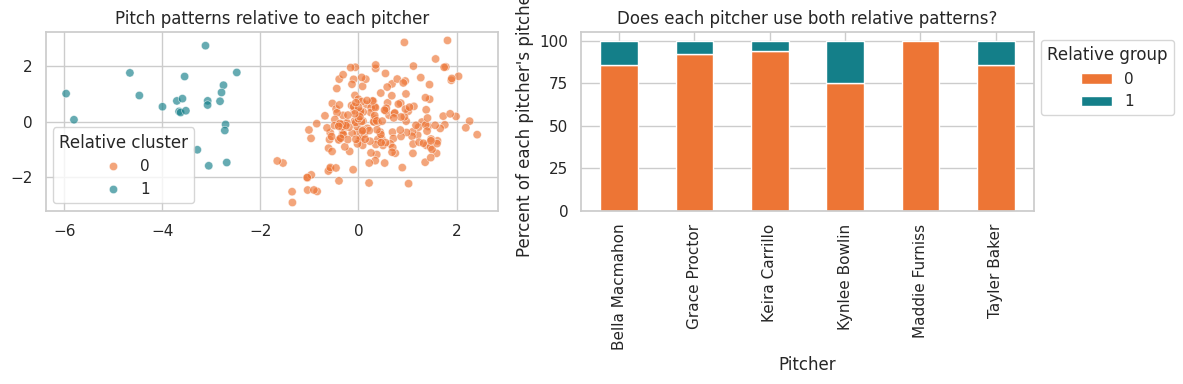

In [15]:
# Center inside each recorded pitcher, then standardize across the dataset.
relative = physical[physical_cols] - physical.groupby("Pitcher")[physical_cols].transform("mean")
relative_scaled = StandardScaler().fit_transform(relative)

relative_scores = []
for k in [2, 3, 4]:
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(relative_scaled)
    relative_scores.append((k, silhouette_score(relative_scaled, labels)))
display(pd.DataFrame(relative_scores, columns=["k", "Silhouette"]).round(3))

relative["Relative cluster"] = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(relative_scaled)
physical["Relative cluster"] = relative["Relative cluster"].values
relative_mix = pd.crosstab(physical["Pitcher"], physical["Relative cluster"], normalize="index") * 100

display(relative_mix.round(1).rename(columns={0: "Relative group 0 (%)", 1: "Relative group 1 (%)"}))
print("Mean deviations from each pitcher's own average in each relative group:")
display(relative.groupby("Relative cluster")[physical_cols].mean().round(2).rename(columns=feature_names))

relative_pc = PCA(n_components=2).fit_transform(relative_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=relative_pc[:, 0], y=relative_pc[:, 1],
                hue=physical["Relative cluster"], palette=["#ED7535", "#147F89"],
                alpha=.65, ax=axes[0], legend=True)
axes[0].set_title("Pitch patterns relative to each pitcher")
relative_mix.plot.bar(stacked=True, ax=axes[1], color=["#ED7535", "#147F89"])
axes[1].set_ylabel("Percent of each pitcher's pitches")
axes[1].set_title("Does each pitcher use both relative patterns?")
axes[1].legend(title="Relative group", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 15. What do individual pitchers' pitch locations look like?
A dot marks where a recorded pitch crossed the plate. The heatmap counts how many pitches crossed each area. **Location is different from horizontal break:** break tells us how the pitch moved; plate location tells us where it ended up.

To avoid false precision, we do not draw a universal official strike zone: the zone depends on the batter, and this dataset does not reliably supply individualized boundaries. A concentration of pitches at a location does **not** by itself mean high pitching success.

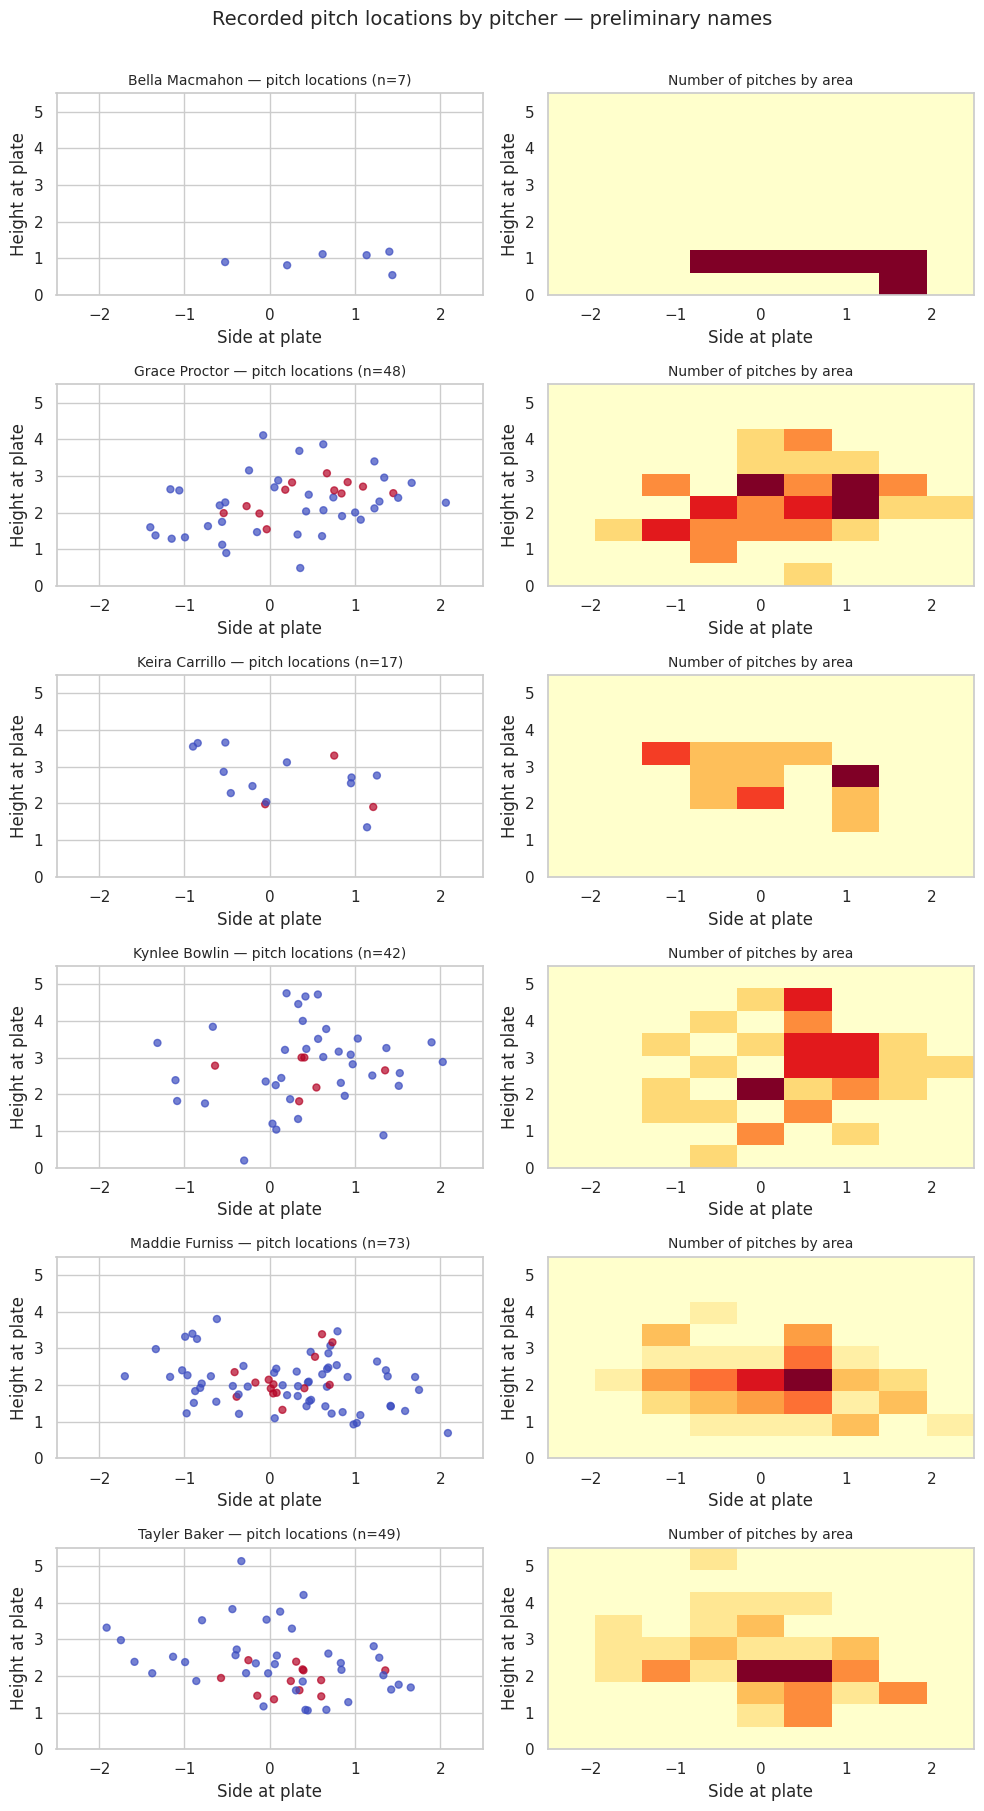

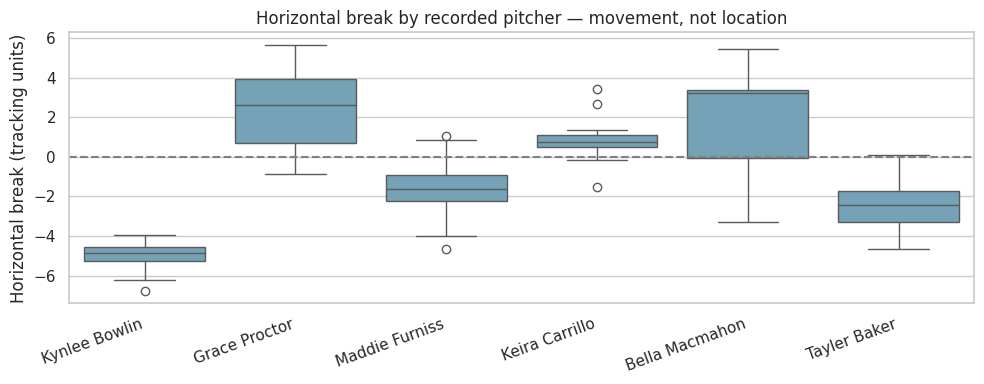

In [16]:
names = sorted(study["Pitcher"].dropna().unique())
fig, axes = plt.subplots(len(names), 2, figsize=(10, 3 * len(names)), squeeze=False)
for row, name in enumerate(names):
    one = study[study["Pitcher"] == name].dropna(subset=["PlateLocSide", "PlateLocHeight"])
    axes[row, 0].scatter(one["PlateLocSide"], one["PlateLocHeight"],
                         c=one["Direct strike"], cmap="coolwarm", vmin=0, vmax=1,
                         s=25, alpha=.7)
    axes[row, 0].set_title(f"{name} — pitch locations (n={len(one)})", fontsize=10)
    axes[row, 1].hist2d(one["PlateLocSide"], one["PlateLocHeight"], bins=9,
                         range=[[-2.5, 2.5], [0, 5.5]], cmap="YlOrRd")
    axes[row, 1].set_title("Number of pitches by area", fontsize=10)
    for ax in axes[row]:
        ax.set(xlim=(-2.5, 2.5), ylim=(0, 5.5), xlabel="Side at plate", ylabel="Height at plate")
plt.suptitle("Recorded pitch locations by pitcher — preliminary names", y=1.005, fontsize=14)
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=study, x="Pitcher", y="HorzBreak", color="#6AA6C1")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(rotation=20, ha="right")
plt.title("Horizontal break by recorded pitcher — movement, not location")
plt.xlabel(""); plt.ylabel("Horizontal break (tracking units)")
plt.tight_layout(); plt.show()

## 16. What did our results really answer?
**Research Question 1 — Which characteristics are associated with outcomes?**  
We (a) calculated descriptive associations for each numerical feature and each of the three outcomes, (b) trained a baseline, logistic regression, and random forest for **each outcome**, (c) compared physical measurements versus game context, and (d) estimated individual predictor importance using held-out permutations. The final comparison shows which *inputs our models relied on*, but not which training change would make a team win more games.

**Research Question 2 — Can we identify pitching styles?**  
We described pitch-speed/spin/movement groups with PCA, silhouette, K-means, and cluster averages. We checked whether those groups were basically one pitcher, then ran a separate pitcher-centered analysis to search for relative patterns within pitchers. **They are exploratory pitch profiles, not confirmed named pitch types or general player styles.**

**What we learned about preprocessing**  
We compared imputation to deletion on the *same evaluation rows*. We also showed a rough interval for their ROC-AUC difference. A result near zero doesn't establish equality or significance, especially with so few pitchers.

**Important limitations before any coaching claim:**
- One game, not a season. Pitches by the same player are related, so uncertainty is high.
- Some tracking pitcher labels disagree with the [official UTA box score](https://utamavs.com/sports/softball/stats/2026/south-dakota-state/boxscore/21014). The held-out-pitcher scores and pitcher groups need rerunning after verified corrections.
- There is no single observed label for "overall success" or "winning". Our three targets are useful but incomplete proxies.
- Plate location is measured as a pitch crosses the plate; that is helpful for *describing outcomes* but may not be fully known **before** the pitch is thrown. The models are exploratory, not real-time pre-pitch decision tools.
- Feature importance and correlation show prediction or association, **not causation**. Future work needs more games, trustworthy pitcher IDs, and coaching input.

**Bottom line:** We have answered both questions *exploratorily* and can explain the boundaries of the results. We should not add more algorithms just to improve a single score.

## 17. Final answers in one place
This last cell brings together the results printed above so the conclusions are easy to present. It does not fit another model.

In [17]:
print("RESEARCH QUESTION 1 — PITCH OUTCOMES")
for outcome in targets:
    one = scores[scores["Outcome"] == outcome].sort_values("ROC-AUC", ascending=False)
    best = one.iloc[0]
    feature = importance[importance["Outcome"] == outcome].sort_values("ROC-AUC drop", ascending=False).iloc[0]
    best_set = set_table[set_table["Outcome"] == outcome].sort_values("ROC-AUC", ascending=False).iloc[0]
    print(f"• {outcome}: {best['Model']} ROC-AUC {best['ROC-AUC']:.3f}; "
          f"top input in full model: {feature['Feature']} "
          f"(AUC drop {feature['ROC-AUC drop']:.3f}); "
          f"best feature group: {best_set['Features']} ({best_set['ROC-AUC']:.3f}).")

print("\nACROSS ALL THREE — NOT AN OVERALL WINNING TARGET")
print("Top three mean permutation effects:", ", ".join(overall.sort_values(ascending=False).head(3).index))

print("\nRESEARCH QUESTION 2 — PITCH PROFILES")
print(f"Main K-means: 2 groups (silhouette {silhouette_rows[0]['Silhouette']:.3f}).")
for label in sorted(physical["Cluster"].unique()):
    part = physical[physical["Cluster"] == label]
    print(f"• Group {label}: {len(part)} pitches, "
          f"average speed {part['RelSpeed'].mean():.1f} mph, "
          f"spin {part['SpinRate'].mean():.0f} RPM.")
print("Global groups were linked to pitcher identity; the relative groups were analyzed separately.")

print("\nIMPUTATION VS DELETION")
for _, row in missing_comparison.iterrows():
    print(f"• {row['Outcome']}: ROC-AUC difference = {row['Difference']:+.3f} (impute - delete).")
print("Final caution: one game and unreconciled pitcher labels; results are exploratory.")

RESEARCH QUESTION 1 — PITCH OUTCOMES
• Direct strike: Random forest ROC-AUC 0.650; top input in full model: Strikes before pitch (AUC drop 0.048); best feature group: Count / location (0.700).
• Strike added: Random forest ROC-AUC 0.779; top input in full model: Strikes before pitch (AUC drop 0.153); best feature group: Count / location (0.826).
• Batter swing: Random forest ROC-AUC 0.672; top input in full model: Strikes before pitch (AUC drop 0.112); best feature group: Count / location (0.723).

ACROSS ALL THREE — NOT AN OVERALL WINNING TARGET
Top three mean permutation effects: Strikes before pitch, Plate height, Plate side

RESEARCH QUESTION 2 — PITCH PROFILES
Main K-means: 2 groups (silhouette 0.520).
• Group 0: 196 pitches, average speed 65.9 mph, spin 1110 RPM.
• Group 1: 40 pitches, average speed 57.7 mph, spin 1467 RPM.
Global groups were linked to pitcher identity; the relative groups were analyzed separately.

IMPUTATION VS DELETION
• Direct strike: ROC-AUC difference = -0.